In [2]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/diabetic_data.csv")

print(df.head())


   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No

In [3]:
print(df.shape)

(101766, 50)


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [6]:
# Inspect missing values

#Replace them:
df = df.replace("?", pd.NA)

#Check missing values:
missing_values = df.isna().sum().sort_values(ascending=False)

print(missing_values.head(15))

weight                 98569
max_glu_serum          96420
A1Cresult              84748
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
patient_nbr                0
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
encounter_id               0
admission_type_id          0
dtype: int64


In [8]:
# Descriptive statistics
numerical_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

summary = df[numerical_columns].describe().T

print(summary)


#Save it:
summary.to_csv("../data/descriptive_statistics.csv")

                       count       mean        std  min   25%   50%   75%  \
time_in_hospital    101766.0   4.395987   2.985108  1.0   2.0   4.0   6.0   
num_lab_procedures  101766.0  43.095641  19.674362  1.0  31.0  44.0  57.0   
num_procedures      101766.0   1.339730   1.705807  0.0   0.0   1.0   2.0   
num_medications     101766.0  16.021844   8.127566  1.0  10.0  15.0  20.0   
number_outpatient   101766.0   0.369357   1.267265  0.0   0.0   0.0   0.0   
number_emergency    101766.0   0.197836   0.930472  0.0   0.0   0.0   0.0   
number_inpatient    101766.0   0.635566   1.262863  0.0   0.0   0.0   1.0   
number_diagnoses    101766.0   7.422607   1.933600  1.0   6.0   8.0   9.0   

                      max  
time_in_hospital     14.0  
num_lab_procedures  132.0  
num_procedures        6.0  
num_medications      81.0  
number_outpatient    42.0  
number_emergency     76.0  
number_inpatient     21.0  
number_diagnoses     16.0  


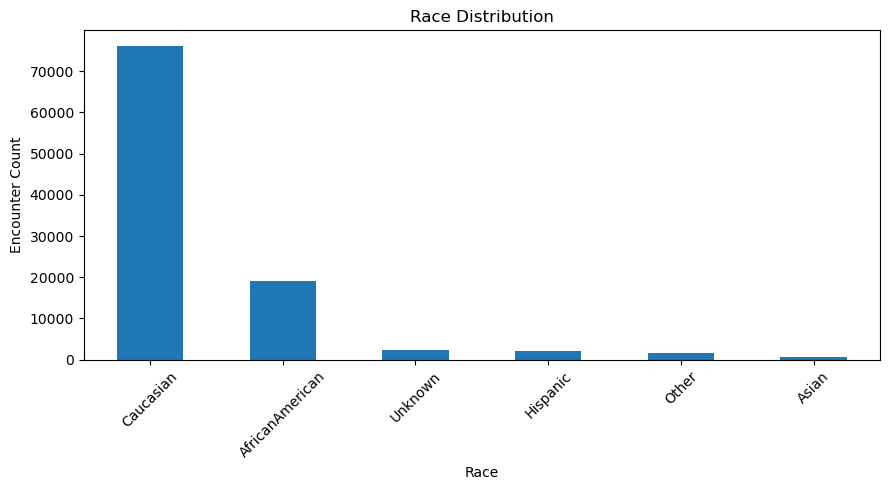

In [9]:
#Visualize race distribution
race_counts = df["race"].fillna("Unknown").value_counts()

plt.figure(figsize=(9, 5))
race_counts.plot(kind="bar")
plt.title("Race Distribution")
plt.xlabel("Race")
plt.ylabel("Encounter Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

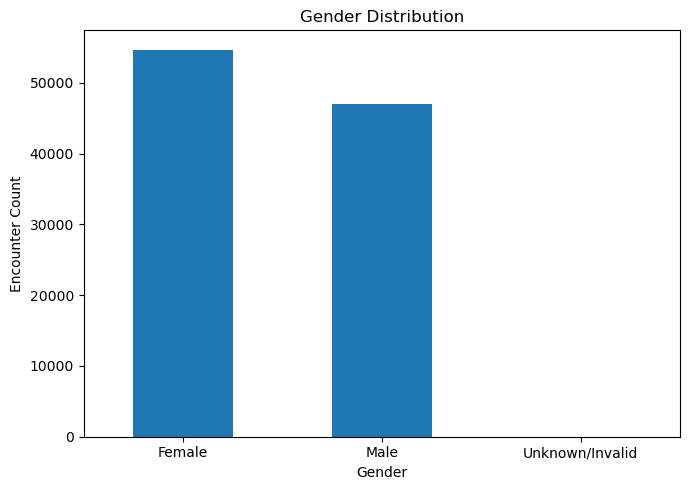

In [10]:
#Visualize gender distribution
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 5))
gender_counts.plot(kind="bar")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Encounter Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
#Readmission status and age
#Create a grouped table:
age_readmission = pd.crosstab(
    df["age"],
    df["readmitted"]
)

print(age_readmission)

readmitted   <30   >30     NO
age                          
[0-10)         3    26    132
[10-20)       40   224    427
[20-30)      236   510    911
[30-40)      424  1187   2164
[40-50)     1027  3278   5380
[50-60)     1668  5917   9671
[60-70)     2502  7897  12084
[70-80)     3069  9475  13524
[80-90)     2078  6223   8896
[90-100)     310   808   1675


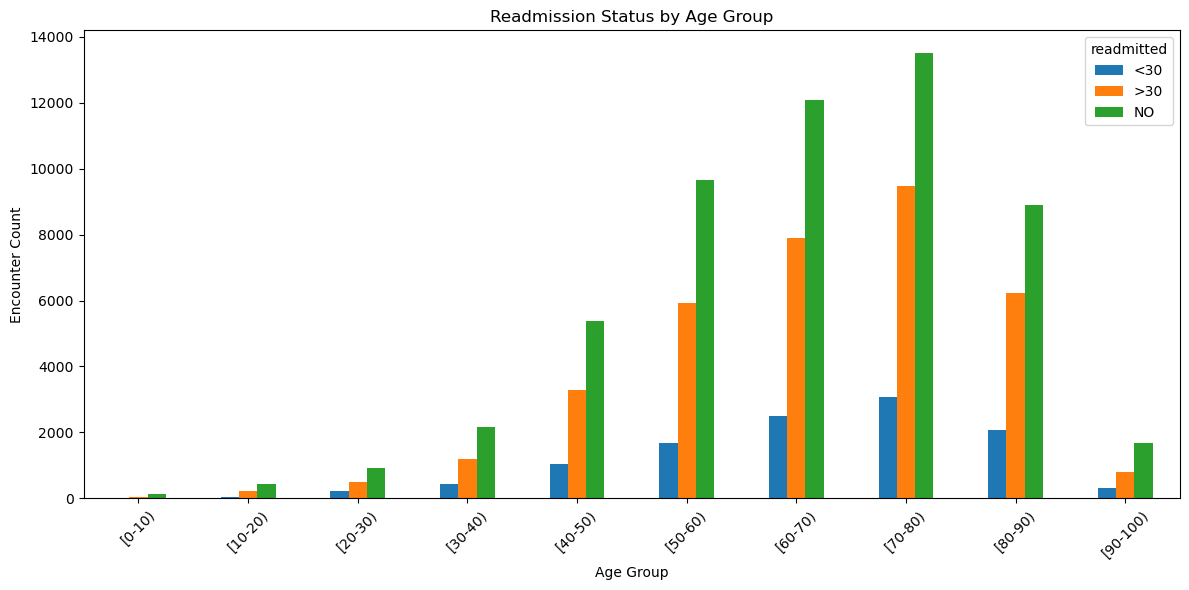

In [12]:
#Create a chart:
age_readmission.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Readmission Status by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Encounter Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
#Investigate correlations
correlation_matrix = df[numerical_columns].corr()

print(correlation_matrix)

                    time_in_hospital  num_lab_procedures  num_procedures  \
time_in_hospital            1.000000            0.318450        0.191472   
num_lab_procedures          0.318450            1.000000        0.058066   
num_procedures              0.191472            0.058066        1.000000   
num_medications             0.466135            0.268161        0.385767   
number_outpatient          -0.008916           -0.007602       -0.024819   
number_emergency           -0.009681           -0.002279       -0.038179   
number_inpatient            0.073623            0.039231       -0.066236   
number_diagnoses            0.220186            0.152773        0.073734   

                    num_medications  number_outpatient  number_emergency  \
time_in_hospital           0.466135          -0.008916         -0.009681   
num_lab_procedures         0.268161          -0.007602         -0.002279   
num_procedures             0.385767          -0.024819         -0.038179   
num_medicat

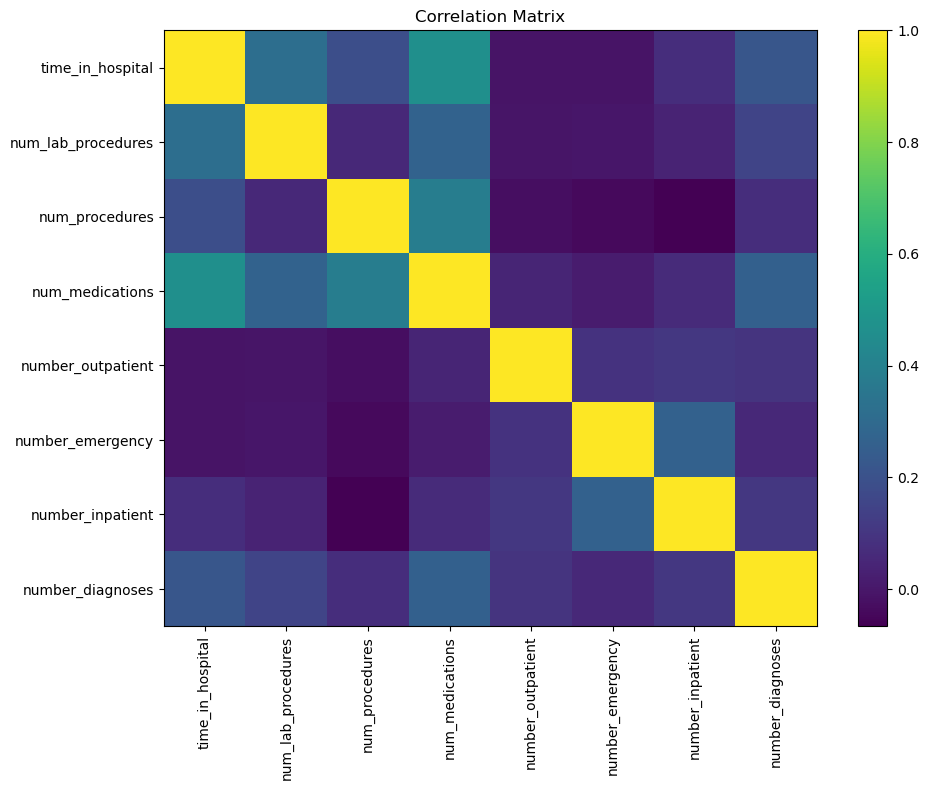

In [14]:
#Correlation Analysis of Numeric Patient and Hospital Variables
plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(numerical_columns)),
    numerical_columns,
    rotation=90
)

plt.yticks(
    range(len(numerical_columns)),
    numerical_columns
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

change
No    54755
Ch    47011
Name: count, dtype: int64


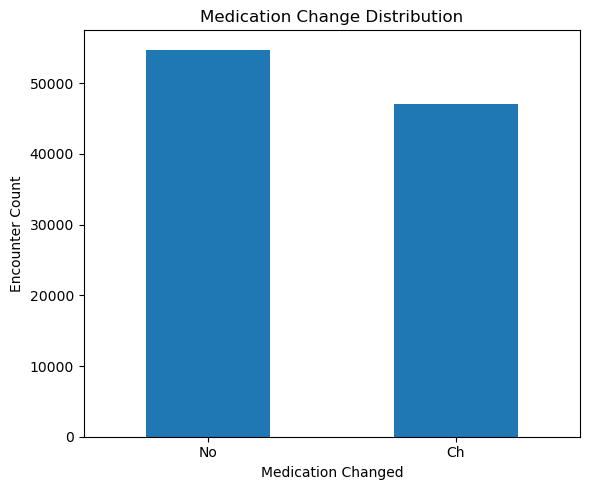

In [15]:
#Medication changes
change_counts = df["change"].value_counts()

print(change_counts)

plt.figure(figsize=(6, 5))
change_counts.plot(kind="bar")
plt.title("Medication Change Distribution")
plt.xlabel("Medication Changed")
plt.ylabel("Encounter Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

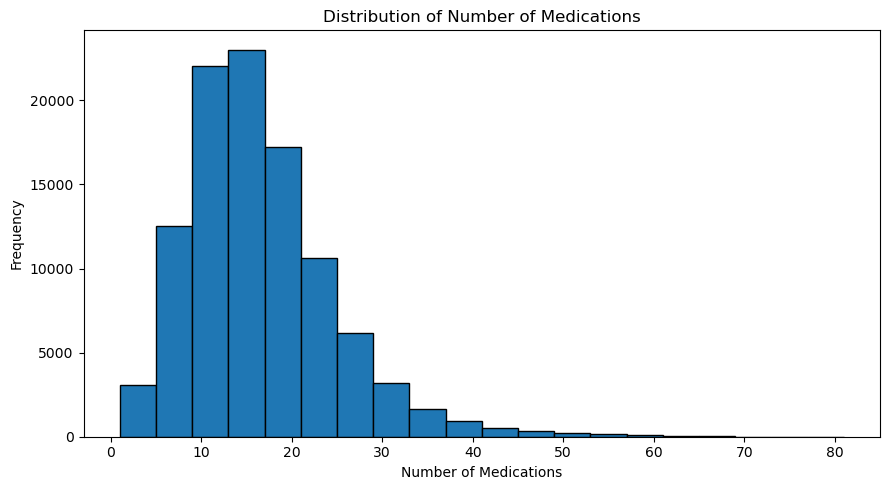

In [16]:
# to Analyze medication count:
plt.figure(figsize=(9, 5))

plt.hist(
    df["num_medications"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Number of Medications")
plt.xlabel("Number of Medications")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64


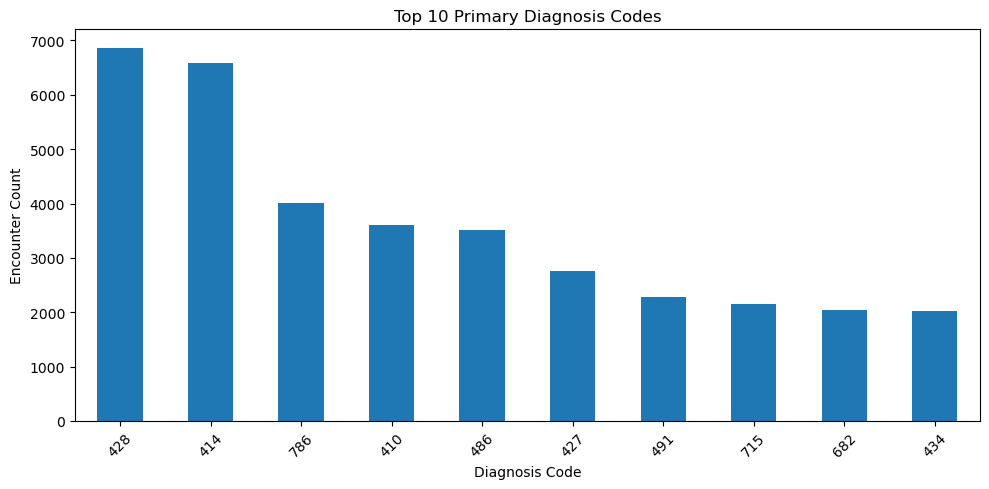

In [17]:
#Diagnose category distribution
#For the primary diagnosis:
top_primary_diagnoses = (
    df["diag_1"]
    .dropna()
    .value_counts()
    .head(10)
)

print(top_primary_diagnoses)

plt.figure(figsize=(10, 5))
top_primary_diagnoses.plot(kind="bar")
plt.title("Top 10 Primary Diagnosis Codes")
plt.xlabel("Diagnosis Code")
plt.ylabel("Encounter Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
#For all diagnosis columns combined:
all_diagnoses = pd.concat(
    [
        df["diag_1"],
        df["diag_2"],
        df["diag_3"]
    ],
    ignore_index=True
)

top_diagnoses = (
    all_diagnoses
    .dropna()
    .value_counts()
    .head(10)
)

print(top_diagnoses)

428    18101
250    17861
276    13816
414    12895
401    12371
427    11757
599     6824
496     5990
403     5693
486     5455
Name: count, dtype: int64


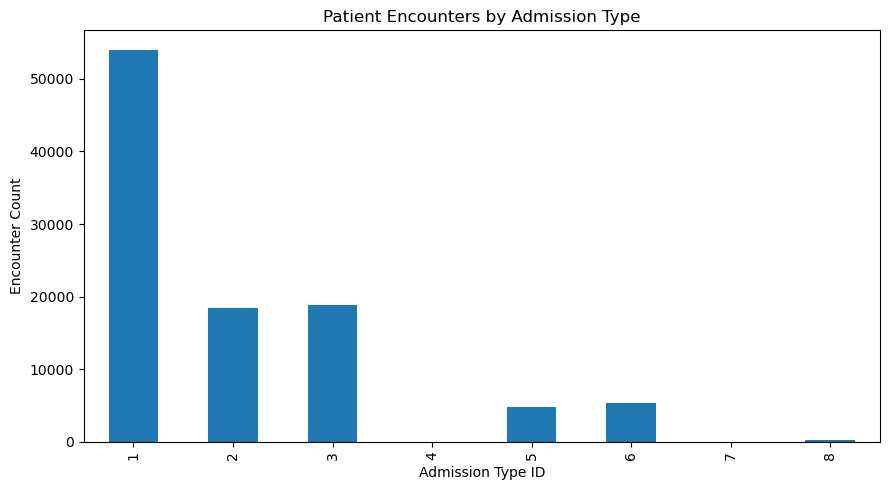

In [19]:
#Admission, source, and discharge distributions
#Admission type:
df["admission_type_id"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Patient Encounters by Admission Type")
plt.xlabel("Admission Type ID")
plt.ylabel("Encounter Count")
plt.tight_layout()
plt.show()

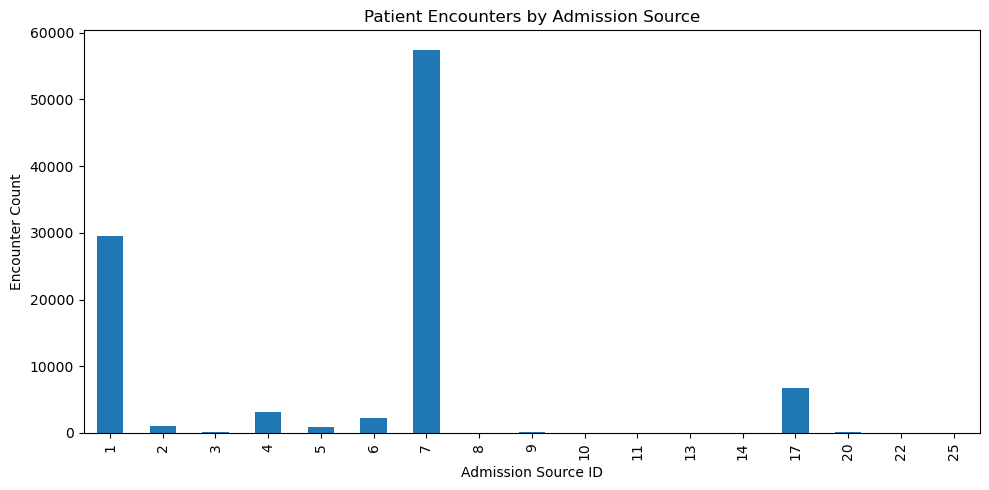

In [20]:
#Admission source:
df["admission_source_id"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Patient Encounters by Admission Source")
plt.xlabel("Admission Source ID")
plt.ylabel("Encounter Count")
plt.tight_layout()
plt.show()

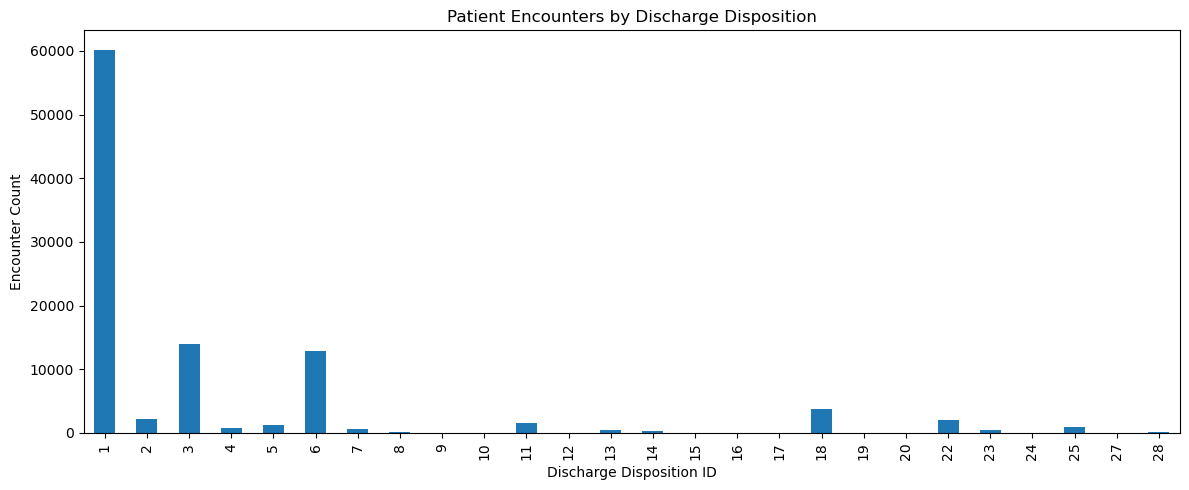

In [21]:
#Discharge disposition:
df["discharge_disposition_id"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Patient Encounters by Discharge Disposition")
plt.xlabel("Discharge Disposition ID")
plt.ylabel("Encounter Count")
plt.tight_layout()
plt.show()

In [22]:
#Identify outliers
#Use the IQR method:
for column in numerical_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        column,
        "Lower:", lower_bound,
        "Upper:", upper_bound,
        "Outliers:", len(outliers)
    )

time_in_hospital Lower: -4.0 Upper: 12.0 Outliers: 2252
num_lab_procedures Lower: -8.0 Upper: 96.0 Outliers: 143
num_procedures Lower: -3.0 Upper: 5.0 Outliers: 4954
num_medications Lower: -5.0 Upper: 35.0 Outliers: 2557
number_outpatient Lower: 0.0 Upper: 0.0 Outliers: 16739
number_emergency Lower: 0.0 Upper: 0.0 Outliers: 11383
number_inpatient Lower: -1.5 Upper: 2.5 Outliers: 7049
number_diagnoses Lower: 1.5 Upper: 13.5 Outliers: 281


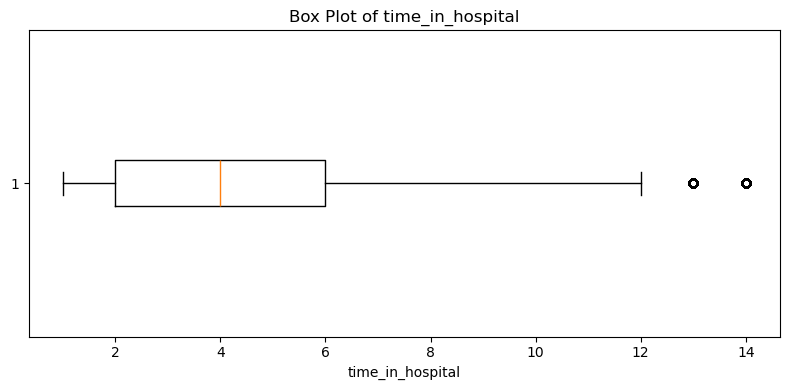

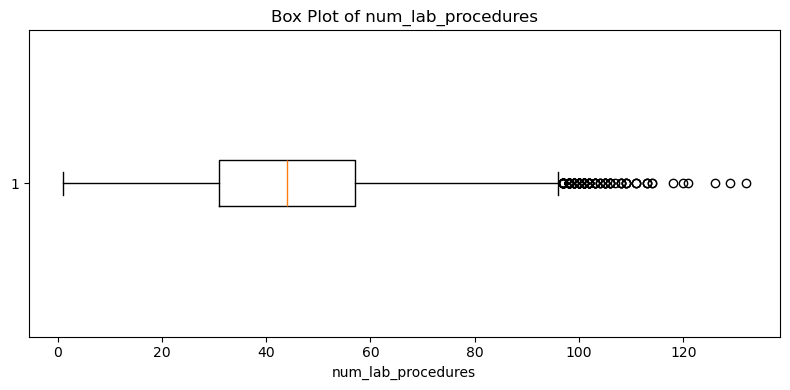

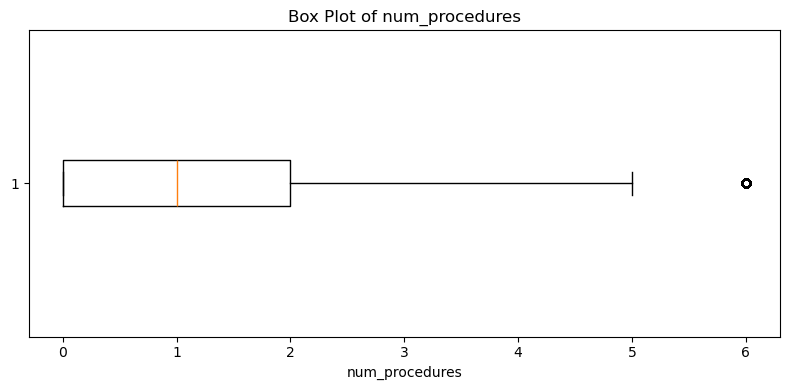

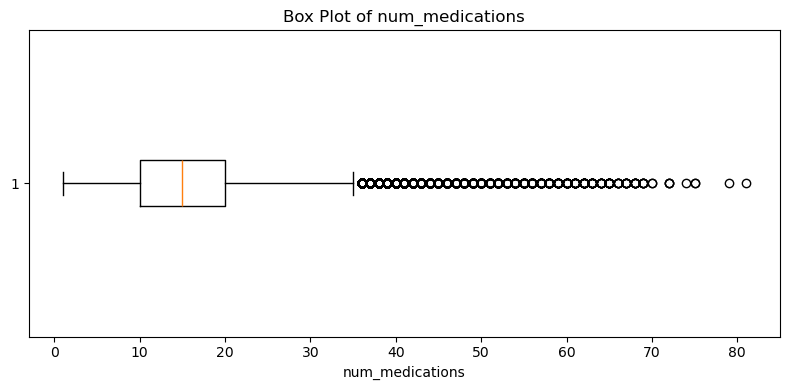

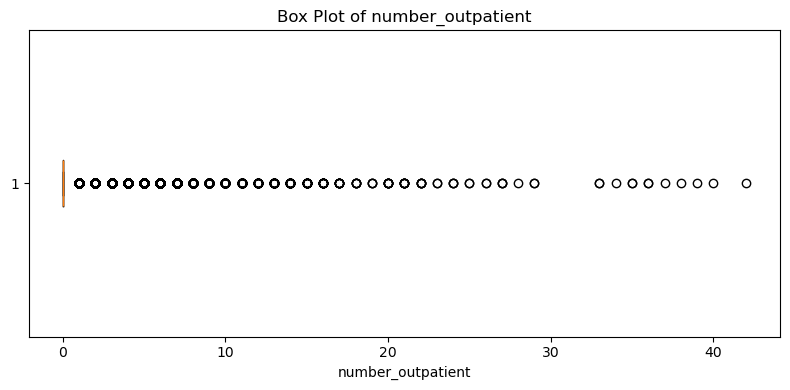

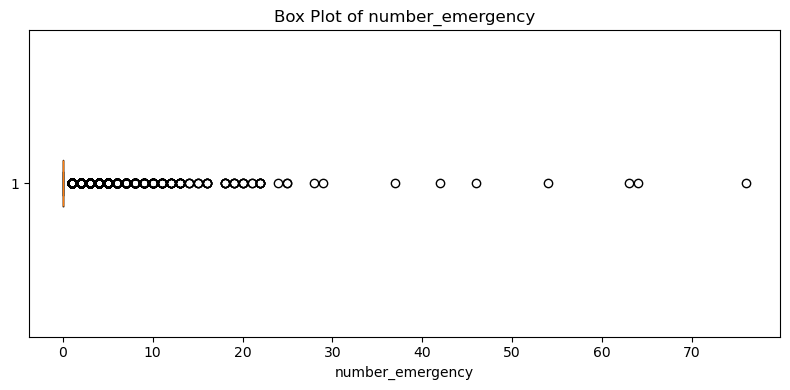

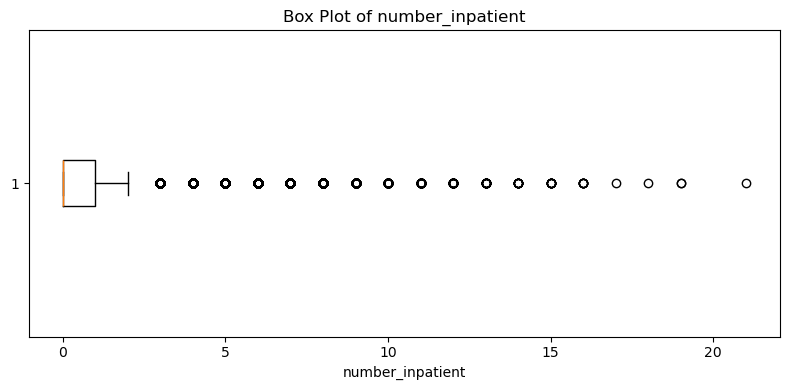

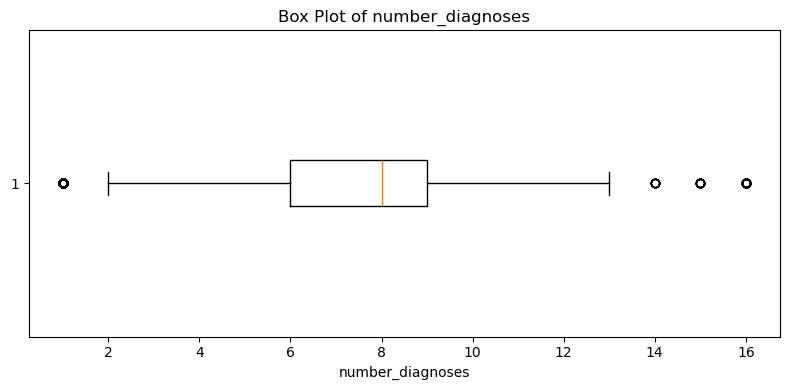

In [23]:
#Create box plots:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [ ]:
#the EDA conclusion

      #The exploratory analysis examined 101,766 patient encounters. Approximately 11.16% of
      #encounters resulted in readmission within 30 days, while 46.09% resulted in readmission 
      #either within or after 30 days. Most encounters involved patients aged between 60 and 80 years. 
      #Numerical analysis showed moderate positive relationships between time in 
      #hospital, laboratory procedures, procedures, and medication counts. Outliers were observed in variables such as 
      #emergency visits, inpatient visits, and medication counts. These records should not be removed automatically 
      #because they may represent high-risk patients who are important to the readmission analysis